In [1]:
# Load the generated C0010 1D results; no CFD report files are read.
from pathlib import Path
import os
import hashlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

CASE_ID = 'C0010'
RESULT_ID = 'C0010R02'
PROJECT_ROOT = Path.cwd().resolve()
while not (PROJECT_ROOT / 'data' / CASE_ID).is_dir():
    if PROJECT_ROOT == PROJECT_ROOT.parent:
        PROJECT_ROOT = Path('D:/eBATS')
        if not (PROJECT_ROOT / 'data' / CASE_ID).is_dir():
            raise FileNotFoundError('Cannot locate the eBATS project.')
        break
    PROJECT_ROOT = PROJECT_ROOT.parent

RESULT_BASENAME = f'{RESULT_ID}_PARK25_ACLC_INTG_1D_EVAL'
CASE_WORKBOOK_DIR = Path(os.environ.get(
    'C0010_CASE_WORKBOOK_DIR',
    PROJECT_ROOT / 'data' / CASE_ID / f'{RESULT_BASENAME}_cases'))
OUTPUT_DIR = Path(os.environ.get('C0010_PLOT_OUTPUT_DIR', PROJECT_ROOT / 'out' / CASE_ID))
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print('项目目录:', PROJECT_ROOT)
print('1D 工况 Excel 目录:', CASE_WORKBOOK_DIR)
print('图片输出目录:', OUTPUT_DIR)


项目目录: D:\eBATS
1D 工况 Excel 目录: D:\eBATS\data\C0010\C0010R02_PARK25_ACLC_INTG_1D_EVAL_cases
图片输出目录: D:\eBATS\out\C0010


In [2]:
AMBIENT_C = 25  # Figure 16 condition (C).

MIN_SAMPLES = 100  # History validation.
START_TOLERANCE_S = 2.0  # Start-time tolerance (s).
END_TOLERANCE_S = 5.0  # End-time tolerance (s).

T_LIMIT = 45.0  # Feasibility and temperature limit lines (C).
DT_LIMIT = 5.0  # Feasibility and temperature-difference limit (C).
DPI = int(os.environ.get('C0010_PLOT_DPI', '900'))  # Figure export resolution.

# Mission metadata used for file loading and plotting.
MISSIONS = {
    'short': dict(
        name='Short-cruise / extended-hover (50 km)',
        abbr='SC-EH',
        folder='M050km_C0633s_H0300s_D1293s',
        cruise=633, hover=300, end=1293, km=50,
    ),
    'baseline': dict(
        abbr='REF',
        name='Baseline mission (100 km)',
        folder='M100km_C1380s_H0180s_D1920s',
        cruise=1380, hover=180, end=1920, km=100,
    ),
    'long': dict(
        abbr='EC-NH',
        name='Extended-cruise / normal-hover (120 km)',
        folder='M120km_C1680s_H0180s_D2220s',
        cruise=1680, hover=180, end=2220, km=120,
    ),
}

mission_table = pd.DataFrame.from_dict(MISSIONS, orient='index')

if not np.isfinite(mission_table[['cruise', 'hover', 'end', 'km']].to_numpy()).all():
    raise ValueError('任务参数必须为有限数值。')
if (mission_table[['cruise', 'hover', 'end', 'km']] <= 0).any().any():
    raise ValueError('任务时长和航程必须为正值。')

# Stages: take-off, ascent, acceleration, cruise, deceleration, descent, hover, landing.
# Indices 3 and 6 are replaced with each mission's cruise and hover durations.
common_stage_durations = np.array([6, 30, 144, 0, 144, 30, 0, 6], dtype=float)

short_durations = common_stage_durations.copy()
short_durations[3] = MISSIONS['short']['cruise']
short_durations[6] = MISSIONS['short']['hover']
MISSIONS['short']['stage_bounds'] = np.r_[0.0, np.cumsum(short_durations)]

baseline_durations = common_stage_durations.copy()
baseline_durations[3] = MISSIONS['baseline']['cruise']
baseline_durations[6] = MISSIONS['baseline']['hover']
MISSIONS['baseline']['stage_bounds'] = np.r_[0.0, np.cumsum(baseline_durations)]

long_durations = common_stage_durations.copy()
long_durations[3] = MISSIONS['long']['cruise']
long_durations[6] = MISSIONS['long']['hover']
MISSIONS['long']['stage_bounds'] = np.r_[0.0, np.cumsum(long_durations)]

if not np.isfinite(np.r_[short_durations, baseline_durations, long_durations]).all():
    raise ValueError('飞行阶段时长必须为有限数值。')
if np.min(np.r_[short_durations, baseline_durations, long_durations]) <= 0:
    raise ValueError('八个飞行阶段的时长都必须为正值。')
mission_table['Stage_total_s'] = [short_durations.sum(), baseline_durations.sum(), long_durations.sum()]
if not np.isclose(mission_table['Stage_total_s'], mission_table['end']).all():
    raise ValueError('阶段时长之和与任务总时长不一致。')

print(mission_table[['name', 'cruise', 'hover', 'end', 'km', 'Stage_total_s']].to_string())

AMBIENT_TEMPERATURES_C = (20, 25, 35)
STAGE_NAMES = ('takeoff', 'climb', 'transition1', 'cruise',
               'transition2', 'descent', 'hover', 'landing')


                                             name  cruise  hover   end   km  Stage_total_s
short       Short-cruise / extended-hover (50 km)     633    300  1293   50         1293.0
baseline                Baseline mission (100 km)    1380    180  1920  100         1920.0
long      Extended-cruise / normal-hover (120 km)    1680    180  2220  120         2220.0


In [3]:
# Require every case, and locate its own C0009-style workbook directly.
case_table = pd.DataFrame(
    [(cooling, mission, ambient)
     for mission in MISSIONS for ambient in AMBIENT_TEMPERATURES_C for cooling in ('AC', 'LC')],
    columns=['Cooling', 'Mission_key', 'Ambient_C'],
)
case_table['CaseID'] = (case_table['Cooling'] + '_' + case_table['Mission_key']
                        + '_T' + case_table['Ambient_C'].astype(str).str.zfill(3) + 'C')
case_table['Workbook'] = case_table['CaseID'].map(
    lambda case_id: CASE_WORKBOOK_DIR / f'{RESULT_BASENAME}_{case_id}.xlsx')
if not CASE_WORKBOOK_DIR.is_dir():
    raise FileNotFoundError(f'Run C0010 EVAL to create the case workbooks: {CASE_WORKBOOK_DIR}')
if len(case_table) != 18 or case_table['CaseID'].duplicated().any():
    raise ValueError('Expected exactly 18 unique 1D cases.')
missing = [str(path) for path in case_table['Workbook'] if not path.is_file()]
if missing:
    raise FileNotFoundError('Missing complete-case Excel files:\n' + '\n'.join(missing))
print(case_table[['CaseID','Workbook']].to_string(index=False))


           CaseID                                                                                                             Workbook
   AC_short_T020C    D:\eBATS\data\C0010\C0010R02_PARK25_ACLC_INTG_1D_EVAL_cases\C0010R02_PARK25_ACLC_INTG_1D_EVAL_AC_short_T020C.xlsx
   LC_short_T020C    D:\eBATS\data\C0010\C0010R02_PARK25_ACLC_INTG_1D_EVAL_cases\C0010R02_PARK25_ACLC_INTG_1D_EVAL_LC_short_T020C.xlsx
   AC_short_T025C    D:\eBATS\data\C0010\C0010R02_PARK25_ACLC_INTG_1D_EVAL_cases\C0010R02_PARK25_ACLC_INTG_1D_EVAL_AC_short_T025C.xlsx
   LC_short_T025C    D:\eBATS\data\C0010\C0010R02_PARK25_ACLC_INTG_1D_EVAL_cases\C0010R02_PARK25_ACLC_INTG_1D_EVAL_LC_short_T025C.xlsx
   AC_short_T035C    D:\eBATS\data\C0010\C0010R02_PARK25_ACLC_INTG_1D_EVAL_cases\C0010R02_PARK25_ACLC_INTG_1D_EVAL_AC_short_T035C.xlsx
   LC_short_T035C    D:\eBATS\data\C0010\C0010R02_PARK25_ACLC_INTG_1D_EVAL_cases\C0010R02_PARK25_ACLC_INTG_1D_EVAL_LC_short_T035C.xlsx
AC_baseline_T020C D:\eBATS\data\C0010\C0010R02_PARK25_A

In [4]:
# Read all three worksheets per case. No combined workbook or index is needed.
RAW_1D_HISTORIES, CASE_SUMMARIES = {}, {}
summary_records, stage_records = [], []
for item in case_table.itertuples(index=False):
    key = (item.Cooling, item.Mission_key, item.Ambient_C)
    case_file = item.Workbook
    with pd.ExcelFile(case_file) as workbook:
        required_sheets = {'Summary', 'Selected', 'Sheet1'}
        if not required_sheets.issubset(workbook.sheet_names):
            raise ValueError(f'Expected Summary / Selected / Sheet1: {case_file}')
        summary = pd.read_excel(workbook, sheet_name='Summary')
        selected = pd.read_excel(workbook, sheet_name='Selected')
        nodes = pd.read_excel(workbook, sheet_name='Sheet1')
    if len(summary) != 1 or summary['model'].iloc[0] != 'Selected':
        raise ValueError(f'Expected exactly one Selected summary row: {case_file}')
    row = summary.iloc[0]
    if row['case_id'] != item.CaseID or row['CaseID'] != item.CaseID:
        raise ValueError(f'Workbook CaseID mismatch: {case_file}')
    if tuple(row[c] for c in ('Cooling','Mission_key','Ambient_C')) != key:
        raise ValueError(f'Workbook condition mismatch: {case_file}')
    # Require EVAL's input/source metadata so mixed stale case files are exposed.
    provenance_columns = ['Input_signature','Input_heat_sha256','Input_model_sha256',
                          'Calculation_code_sha256','Result_origin','Result_source','Action']
    if any(column not in row or pd.isna(row[column]) for column in provenance_columns):
        raise ValueError(f'Run the updated EVAL once to add reuse/source metadata: {case_file}')
    for column in ('Input_signature','Input_heat_sha256','Input_model_sha256','Calculation_code_sha256'):
        value = str(row[column])
        if len(value) != 64 or any(c not in '0123456789abcdef' for c in value):
            raise ValueError(f'Invalid reuse signature {column}: {case_file}')
    if row['Result_origin'] not in ('computed','upstream') or row['Action'] not in ('computed','cache','upstream'):
        raise ValueError(f'Invalid calculation/source status: {case_file}')
    heat_file = Path(row['Heat_source'])
    model_file = PROJECT_ROOT/'lib/BTMS_model.py'
    for path, column in [(heat_file,'Input_heat_sha256'),(model_file,'Input_model_sha256')]:
        if path.is_file() and hashlib.sha256(path.read_bytes()).hexdigest() != row[column]:
            raise ValueError(f'Inputs changed after this case was generated; rerun EVAL: {case_file}')
    duration, dt = float(row['simulation_duration_s']), float(row['dt_s'])
    if not np.isfinite([duration,dt]).all() or duration <= 0 or dt <= 0:
        raise ValueError(f'Invalid duration or time step: {case_file}')
    steps = int(round(duration/dt))
    if not np.isclose(steps*dt,duration,atol=1e-8,rtol=0):
        raise ValueError(f'Duration is not an integer number of steps: {case_file}')
    node_columns = ['time', *[f'T_bat_{i+1}' for i in range(20)], *[f'T_cool_{i+1}' for i in range(20)]]
    if list(nodes.columns) != node_columns:
        raise ValueError(f'Sheet1 must use C0009 time / T_bat_1..20 / T_cool_1..20 columns: {case_file}')
    outlet = 'Twater_out_C' if item.Cooling == 'LC' else 'Tair_out_C'
    medium = 'T_water' if item.Cooling == 'LC' else 'T_air'
    required = ['time_s','Tmax_C','Tmin_C','DeltaT_C',outlet]
    required += [f'T_bat_seg_{i+1:02d}_C' for i in range(20)]
    required += [f'{medium}_seg_{i+1:02d}_C' for i in range(20)]
    if not set(required).issubset(selected.columns):
        raise ValueError(f'Selected is missing full-history/segment columns: {case_file}')
    time = selected['time_s'].to_numpy(dtype=float)
    expected_time = np.arange(steps+1)*dt
    if len(time) != steps+1 or not np.allclose(time,expected_time,atol=1e-8,rtol=0):
        raise ValueError(f'Incomplete or repeated mission time records: {case_file}')
    if len(nodes) != len(time) or not np.allclose(nodes['time'],time,atol=1e-8,rtol=0):
        raise ValueError(f'Selected and Sheet1 time axes differ: {case_file}')
    values = nodes.to_numpy(dtype=float)
    if not np.isfinite(values).all() or not np.isfinite(selected[required].to_numpy(dtype=float)).all():
        raise ValueError(f'Invalid full-mission temperature data: {case_file}')
    bat, cool = values[:,1:21], values[:,21:41]
    for column, actual in [('Tmax_C',bat.max(axis=1)),('Tmin_C',bat.min(axis=1)),
                           ('DeltaT_C',np.ptp(bat,axis=1)),(outlet,cool[:,-1])]:
        if not np.allclose(selected[column],actual,atol=1e-8,rtol=0):
            raise ValueError(f'Selected / Sheet1 mismatch in {column}: {case_file}')
    for i in range(20):
        if not np.allclose(selected[f'T_bat_seg_{i+1:02d}_C'],bat[:,i],atol=1e-8,rtol=0):
            raise ValueError(f'Battery segment {i+1} mismatch: {case_file}')
        if not np.allclose(selected[f'{medium}_seg_{i+1:02d}_C'],cool[:,i],atol=1e-8,rtol=0):
            raise ValueError(f'Coolant segment {i+1} mismatch: {case_file}')
    history = selected.copy()
    history['Tmean_C'] = bat.mean(axis=1)
    history['Tcool_out_C'] = selected[outlet]
    for column in ('CaseID','Cooling','Mission_key','Ambient_C'):
        history[column] = row[column]

    starts = np.array([row[f'stage_{stage}_start_s'] for stage in STAGE_NAMES],dtype=float)
    ends = np.array([row[f'stage_{stage}_end_s'] for stage in STAGE_NAMES],dtype=float)
    if (not np.isfinite(np.r_[starts,ends]).all() or np.any(ends<=starts)
        or not np.isclose(starts[0],0) or not np.isclose(ends[-1],duration)
        or not np.allclose(starts[1:],ends[:-1],atol=1e-8,rtol=0)):
        raise ValueError(f'Invalid eight-stage mission boundaries: {case_file}')
    bounds = np.r_[starts[0],ends]
    if not np.isclose(ends[3]-starts[3],row['cruise_s']) or not np.isclose(ends[6]-starts[6],row['hover_s']):
        raise ValueError(f'Cruise/hover duration differs from stage boundaries: {case_file}')
    metadata = dict(cruise=float(row['cruise_s']),hover=float(row['hover_s']),
                    end=duration,km=float(row['Distance_km']),stage_bounds=bounds)
    mission = MISSIONS[item.Mission_key]
    if mission:
        if not np.allclose(mission['stage_bounds'],bounds,atol=1e-8,rtol=0):
            raise ValueError(f'The same mission has inconsistent stage timings: {case_file}')
        if any(not np.isclose(mission[k],metadata[k]) for k in ('cruise','hover','end','km')):
            raise ValueError(f'The same mission has inconsistent metadata: {case_file}')
    else:
        mission.update(metadata)
        mission_labels = {'short':'Short-cruise / extended-hover',
                          'baseline':'Baseline mission','long':'Long-cruise / normal-hover'}
        mission['name'] = f"{mission_labels[item.Mission_key]} ({metadata['km']:g} km)"
    for stage,start,end in zip(STAGE_NAMES,starts,ends):
        match = np.flatnonzero(np.isclose(time,end,atol=1e-8,rtol=0))
        if len(match) != 1:
            raise ValueError(f'Missing {stage} endpoint in the full history: {case_file}')
        index = int(match[0])
        mask = (time>=start-1e-8)&(time<=end+1e-8)
        stage_records.append(dict(CaseID=item.CaseID,Cooling=item.Cooling,
            Mission_key=item.Mission_key,Ambient_C=item.Ambient_C,Stage=stage,
            start_s=start,end_s=end,Tmax_C=float(history.loc[mask,'Tmax_C'].max()),
            DeltaTmax_C=float(history.loc[mask,'DeltaT_C'].max()),
            end_Tmax_C=float(history.loc[index,'Tmax_C']),
            end_Tmin_C=float(history.loc[index,'Tmin_C']),
            end_Tmean_C=float(history.loc[index,'Tmean_C'])))
    RAW_1D_HISTORIES[key] = history
    CASE_SUMMARIES[key] = row.to_dict()
    summary_records.append(row.to_dict())

model_summary = pd.DataFrame(summary_records).set_index(['Cooling','Mission_key','Ambient_C'])
STAGE_RESULTS = pd.DataFrame(stage_records)
if len(model_summary) != 18 or len(STAGE_RESULTS) != 144:
    raise ValueError('Expected 18 complete cases and 144 flight-stage records.')
# Retain provenance for downstream comparisons and make mixed model revisions fail.
source_table = pd.DataFrame(summary_records)
for column in ('Input_model_sha256','Calculation_code_sha256','Property_version'):
    if source_table[column].nunique() != 1:
        raise ValueError(f'Mixed calculation versions in case workbooks: {column}. Rerun EVAL.')
DATA_SOURCES = source_table[['CaseID','Action','Result_origin','Result_source','Reuse_note']].copy()
print('Data sources:')
print(DATA_SOURCES[['CaseID','Action','Result_origin']].to_string(index=False))
mission_table = pd.DataFrame.from_dict(MISSIONS,orient='index')
case_table['Status'] = 'Loaded complete case Excel'
print(mission_table[['name','cruise','hover','end','km']].to_string())
print(case_table[['CaseID','Status']].to_string(index=False))
print('Loaded 18 complete cases and all 144 stages directly from the case workbooks.')


Data sources:
           CaseID   Action Result_origin
   AC_short_T020C computed      computed
   LC_short_T020C computed      computed
   AC_short_T025C computed      computed
   LC_short_T025C computed      computed
   AC_short_T035C computed      computed
   LC_short_T035C computed      computed
AC_baseline_T020C computed      computed
LC_baseline_T020C upstream      upstream
AC_baseline_T025C upstream      upstream
LC_baseline_T025C upstream      upstream
AC_baseline_T035C computed      computed
LC_baseline_T035C upstream      upstream
    AC_long_T020C computed      computed
    LC_long_T020C computed      computed
    AC_long_T025C computed      computed
    LC_long_T025C computed      computed
    AC_long_T035C computed      computed
    LC_long_T035C computed      computed
                                             name  cruise  hover   end   km
short       Short-cruise / extended-hover (50 km)     633    300  1293   50
baseline                Baseline mission (100 km)    13

In [5]:
# Adapt native 1D Celsius histories to the reference plotting interface.
# Tmid_C preserves the reference boundary midpoint; Tmean_C retains the node mean.
MODEL_HISTORIES, MODEL_EXTREMA, summary_rows = {}, {}, []
for key, history in RAW_1D_HISTORIES.items():
    cooling, mission_key, ambient = key
    mission = MISSIONS[mission_key]
    time = history['time_s'].to_numpy(dtype=float)
    upper = history['Tmax_C'].to_numpy(dtype=float)
    lower = history['Tmin_C'].to_numpy(dtype=float)
    mean = history['Tmean_C'].to_numpy(dtype=float)
    difference = upper - lower
    if np.any(difference < -1e-8) or np.any(mean < lower-1e-8) or np.any(mean > upper+1e-8):
        raise ValueError(f'Inconsistent 1D temperature bounds: {key}')
    if not np.allclose(difference, history['DeltaT_C'], atol=1e-8, rtol=0):
        raise ValueError(f'1D DeltaT differs from Tmax-Tmin: {key}')
    if not np.allclose([upper[0], lower[0], mean[0]], ambient, atol=1e-8, rtol=0):
        raise ValueError(f'Unexpected initial 1D temperature: {key}')
    peak_index, difference_index = int(np.argmax(upper)), int(np.argmax(difference))
    peak = {
        'Tmax_C': float(upper[peak_index]), 
        'Tmax_time_s': float(time[peak_index]),
        'DTmax_C': float(difference[difference_index]), 
        'DTmax_time_s': float(time[difference_index]),
        'DTmax_upper_C': float(upper[difference_index]), 
        'DTmax_lower_C': float(lower[difference_index]),
    }
    reference = model_summary.loc[key]
    measured = [peak['Tmax_C'], peak['DTmax_C'], peak['Tmax_time_s'], peak['DTmax_time_s']]
    exported = reference[['Tmax_C', 'DeltaTmax_C', 'time_of_Tmax_s', 'time_of_DeltaTmax_s']].to_numpy(dtype=float)
    if not np.allclose(measured, exported, atol=1e-8, rtol=0):
        raise ValueError(f'1D history and Summary worksheet disagree: {key}')
    MODEL_HISTORIES[key] = {
        'time_s': time, 'Tmax_C': upper, 'Tmin_C': lower,
        'Tmean_C': mean, 'Tmid_C': (upper + lower) / 2,
        'DT_C': difference, 'source': '1D',
    }
    MODEL_EXTREMA[key] = peak
    summary_rows.append({
        'Mission': mission['name'], 'Mission_key': mission_key,
        'Cooling': cooling, 'Ambient_C': ambient,
        'hover': mission['hover'], 'end': mission['end'],
        'Source': '1D', **peak,
        'T_margin_C': T_LIMIT-peak['Tmax_C'], 'DT_margin_C': DT_LIMIT-peak['DTmax_C'],
        'Feasible': peak['Tmax_C'] <= T_LIMIT and peak['DTmax_C'] <= DT_LIMIT,
    })
df_fig17 = pd.DataFrame(summary_rows)
print(df_fig17[['Mission', 'Cooling', 'Ambient_C', 'Tmax_C', 'DTmax_C', 'Feasible']].to_string(index=False))


                                Mission Cooling  Ambient_C    Tmax_C  DTmax_C  Feasible
  Short-cruise / extended-hover (50 km)      AC         20 46.516315 5.043422     False
  Short-cruise / extended-hover (50 km)      LC         20 32.866804 4.458525      True
  Short-cruise / extended-hover (50 km)      AC         25 51.602433 5.087628     False
  Short-cruise / extended-hover (50 km)      LC         25 37.801489 4.491755      True
  Short-cruise / extended-hover (50 km)      AC         35 61.770652 5.174017     False
  Short-cruise / extended-hover (50 km)      LC         35 47.685468 4.546534     False
              Baseline mission (100 km)      AC         20 39.719745 3.468477      True
              Baseline mission (100 km)      LC         20 31.170669 3.151755      True
              Baseline mission (100 km)      AC         25 44.786914 3.508472      True
              Baseline mission (100 km)      LC         25 36.133956 3.189105      True
              Baseline mission (

In [6]:
# Figure 16: select the six histories and extrema at the configured ambient temperature.
# Prepare plotting inputs here so each plot cell can run independently.
FIG16_DATA = {
    ('short', 'AC'): MODEL_HISTORIES[('AC', 'short', AMBIENT_C)],
    ('short', 'LC'): MODEL_HISTORIES[('LC', 'short', AMBIENT_C)],
    ('baseline', 'AC'): MODEL_HISTORIES[('AC', 'baseline', AMBIENT_C)],
    ('baseline', 'LC'): MODEL_HISTORIES[('LC', 'baseline', AMBIENT_C)],
    ('long', 'AC'): MODEL_HISTORIES[('AC', 'long', AMBIENT_C)],
    ('long', 'LC'): MODEL_HISTORIES[('LC', 'long', AMBIENT_C)],
}
FIG16_EXTREMA = {
    ('short', 'AC'): MODEL_EXTREMA[('AC', 'short', AMBIENT_C)],
    ('short', 'LC'): MODEL_EXTREMA[('LC', 'short', AMBIENT_C)],
    ('baseline', 'AC'): MODEL_EXTREMA[('AC', 'baseline', AMBIENT_C)],
    ('baseline', 'LC'): MODEL_EXTREMA[('LC', 'baseline', AMBIENT_C)],
    ('long', 'AC'): MODEL_EXTREMA[('AC', 'long', AMBIENT_C)],
    ('long', 'LC'): MODEL_EXTREMA[('LC', 'long', AMBIENT_C)],
}
FIG16_TABLE = df_fig17.loc[df_fig17['Ambient_C'] == AMBIENT_C].reset_index(drop=True).copy()
if len(FIG16_TABLE) != 6:
    raise ValueError('Figure 16 必须包含三种任务、两种冷却方案的六组数据。')

print('Figure 16 工况数:', len(FIG16_TABLE))
print('Figure 17 工况数:', len(df_fig17))
print('可行工况数:', int(df_fig17['Feasible'].sum()))


Figure 16 工况数: 6
Figure 17 工况数: 18
可行工况数: 9


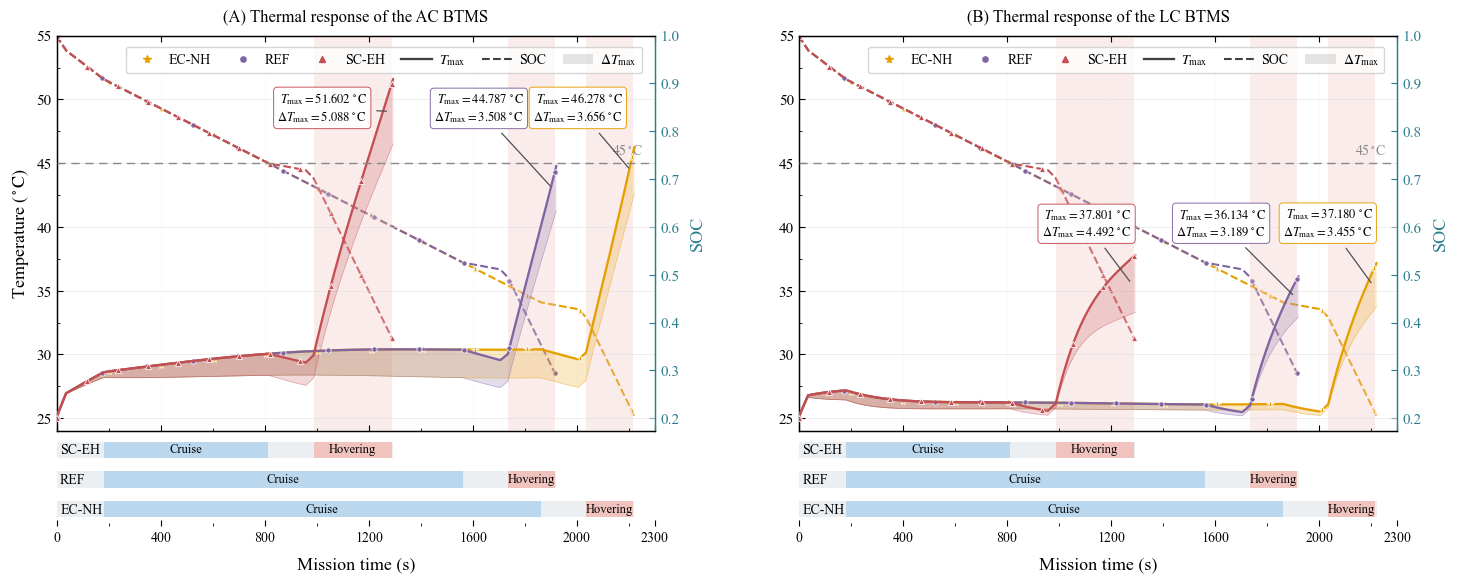

PNG: D:\eBATS\out\C0010\C0010R02_PARK25_ACLC_INTG_1D_CMP_mission_thermal_response.png
PDF: D:\eBATS\out\C0010\C0010R02_PARK25_ACLC_INTG_1D_CMP_mission_thermal_response.pdf


In [7]:
# Figure 16: create the figure, plot curves, then add bands and annotations.
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse, Patch
from matplotlib.ticker import AutoMinorLocator

font_size = 12
plt.rcParams.update({
    'font.family': 'Times New Roman',
    'mathtext.fontset': 'stix',
    'font.size': font_size,
    'axes.labelsize': font_size,
    'axes.titlesize': font_size,
    'xtick.labelsize': font_size - 1,
    'ytick.labelsize': font_size - 1,
    'axes.linewidth': 0.9,
    'xtick.direction': 'in',
    'ytick.direction': 'in',
    'xtick.major.width': 0.8,
    'ytick.major.width': 0.8,
    'xtick.major.size': 4,
    'ytick.major.size': 4,
    'axes.unicode_minus': False,
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
})

# Create the canvas.
fig16, axes = plt.subplots(2, 2, figsize=(15.5, 7.0), facecolor='white', sharex='col', gridspec_kw=dict(height_ratios=[4.5, 1.05], wspace=0.1, hspace=0.01))
fig16.subplots_adjust(left=0.085, right=0.99, bottom=0.19, top=0.89)
ax_ac, ax_lc = axes[0]
ax_stage_ac, ax_stage_lc = axes[1]

ac_short = FIG16_DATA[('short', 'AC')]
ac_baseline = FIG16_DATA[('baseline', 'AC')]
ac_long = FIG16_DATA[('long', 'AC')]
lc_short = FIG16_DATA[('short', 'LC')]
lc_baseline = FIG16_DATA[('baseline', 'LC')]
lc_long = FIG16_DATA[('long', 'LC')]

curve_dict = {
    'ac_long': {
        "mission": "Long", 
        "abbr": MISSIONS["long"]["abbr"],
        "cooling": "AC", 
        "data": ac_long,
        "peak": FIG16_EXTREMA[('long', 'AC')],
        "stage_bounds": MISSIONS["long"]['stage_bounds'],
        "offset_text": (-45, 3),
        "y_stage": 0},    
    'ac_baseline': {
        "mission": "Baseline", 
        "abbr": MISSIONS["baseline"]["abbr"],
        "cooling": "AC", 
        "data": ac_baseline,
        "peak": FIG16_EXTREMA[('baseline', 'AC')],
        "stage_bounds": MISSIONS["baseline"]['stage_bounds'],
        "offset_text": (-125, 3),
        "y_stage": 1},
    'ac_short': {
        "mission": "Short", 
        "abbr": MISSIONS["short"]["abbr"],
        "cooling": "AC", 
        "data": ac_short,
        "peak": FIG16_EXTREMA[('short', 'AC')],
        "stage_bounds": MISSIONS["short"]['stage_bounds'],
        "offset_text": (-100, 3),
        "y_stage": 2},
    'lc_long': {
        "mission": "Long", 
        "abbr": MISSIONS["long"]["abbr"],
        "cooling": "LC", 
        "data": lc_long,
        "peak": FIG16_EXTREMA[('long', 'LC')],
        "stage_bounds": MISSIONS["long"]['stage_bounds'],
        "offset_text": (-15, -6),
        "y_stage": 0},
    'lc_baseline': {
        "mission": "Baseline", 
        "abbr": MISSIONS["baseline"]["abbr"],
        "cooling": "LC", 
        "data": lc_baseline,
        "peak": FIG16_EXTREMA[('baseline', 'LC')],
        "offset_text": (-125, -6),
        "stage_bounds": MISSIONS["baseline"]['stage_bounds'],
        "y_stage": 1},
    'lc_short': {
        "mission": "Short", 
        "abbr": MISSIONS["short"]["abbr"],
        "cooling": "LC", 
        "data": lc_short,
        "peak": FIG16_EXTREMA[('short', 'LC')],
        "offset_text": (-15, -6),
        "stage_bounds": MISSIONS["short"]['stage_bounds'],
        "y_stage": 2},
}


line_style = {
    'Short': dict(color='#C44E52', marker='^', markersize=4.2),
    'Baseline': dict(color='#8064A2', marker='o', markersize=3.8),
    'Long': dict(color='#E69F00', marker='*', markersize=5.8),
}
curve_style = dict(linestyle='-', linewidth=1.65, markeredgecolor='white', markeredgewidth=0.55, solid_capstyle='round', zorder=5)

band_style = dict(alpha=0.22, edgecolor='none', zorder=2)
boundary_style = dict(linewidth=0.50, alpha=0.50, zorder=3)
# Add six independent extrema callouts; edit xytext to move a label.
ellipse_style = dict(width=95.0, facecolor='none', linewidth=1.35, linestyle=(0, (3.0, 2.2)), zorder=12)
box_style = dict(boxstyle='round,pad=0.30', facecolor='white', linewidth=0.7, alpha=0.95)
callout_style = dict(xycoords='data', textcoords='data', ha='right', va='bottom', fontsize=font_size - 3, annotation_clip=False, zorder=15,
                    arrowprops=dict(arrowstyle='-', color='#505050', linewidth=0.9, shrinkA=4, shrinkB=2))
bar_style = dict(height=0.54, edgecolor='none')
stage_text_style = dict(ha='center', va='center', fontsize=font_size - 3)
hover_style = dict(color='#F0C3BE', alpha=0.30, linewidth=0, zorder=0)


# Add the design limit.
limit_style = dict(color='#888888', linewidth=1.0, linestyle=(0, (6, 4)), zorder=6)
limit_text_style = dict(xycoords=('axes fraction', 'data'), xytext=(-8, 4), textcoords='offset points', ha='right', va='bottom', fontsize=font_size - 2, color='#888888')

# Set axes and grids.
time_max = max(2300, MISSIONS['short']['end'], MISSIONS['baseline']['end'], MISSIONS['long']['end'])
all_lower = np.concatenate((ac_short['Tmin_C'], ac_baseline['Tmin_C'], ac_long['Tmin_C'], lc_short['Tmin_C'], lc_baseline['Tmin_C'], lc_long['Tmin_C']))
limits = dict(xlim=(0, time_max), ylim=(min(24, float(np.floor(all_lower.min() - 1))), max(55, float(np.ceil(FIG16_TABLE['Tmax_C'].max() + 1)))))
limits['xticks'] = np.r_[np.arange(0, time_max, 400), time_max]
limits['yticks'] = np.arange(np.ceil(limits['ylim'][0] / 5) * 5, limits['ylim'][1] + 0.01, 5)

stage_limits = dict(ylim=(-0.55, 2.55), yticks=[2,1,0], yticklabels=['Short', 'Baseline', 'Long'])
# Plot the six midpoint curves.

y_annotation = 45

for key, value in curve_dict.items():
    ax = ax_ac if value['cooling'] == 'AC' else ax_lc
    ax_stage = ax_stage_ac if value['cooling'] == 'AC' else ax_stage_lc
    
    val_mid = value['data']['Tmid_C']
    val_max = value['data']['Tmax_C']
    val_min = value['data']['Tmin_C']
    val_time = value['data']['time_s']
    mission_name = value['mission']
    mission_abbr = value['abbr']
    
    line, = ax.plot(
        val_time,
        val_max,
        markevery=max(1, len(value['data']['time_s']) // 11),
        label=mission_abbr,
        **line_style[mission_name],
        **curve_style
    )
    
    ax.fill_between(
        val_time,
        val_min,
        val_max,
        color=line_style[mission_name]['color'],
        **band_style
    )
    
    ax.plot(
        val_time,
        np.column_stack((val_max, val_min)),
        color=line_style[mission_name]['color'],
        **boundary_style
    )
    
    stage_bounds = value['stage_bounds']
    
    # Add the red hovering backgrounds using the same boundaries as the timelines.
    ax.axvspan(stage_bounds[6], stage_bounds[7], **hover_style)

    peak = value['peak']
    center_x = peak['DTmax_time_s']
    center_y = (peak['DTmax_upper_C'] + peak['DTmax_lower_C']) / 2
    offset_x, offset_y = value["offset_text"]
    
    label = rf'$T_\max={peak["Tmax_C"]:.3f}\,^\circ\mathrm{{C}}$' + '\n' + rf'$\Delta T_\max={peak["DTmax_C"]:.3f}\,^\circ\mathrm{{C}}$'
    # print(f'line color for mission {mission_name} is', line_style)
    # ax.add_patch(Ellipse((center_x, center_y), height=peak['DTmax_C'] + 1.20, 
    # edgecolor=line_style[mission_name]['color'], **ellipse_style))    
  
    # Annotation for the peak temperature at the center of the ellipse
    ax.annotate(
        label, 
        xy=(center_x - 15, center_y), 
        xytext=(center_x + offset_x, y_annotation + offset_y), 
        bbox=dict(box_style, edgecolor=line_style[mission_name]['color']), 
        **callout_style)
    
    y_stage = value['y_stage']
    
    ax_stage.barh(y_stage, stage_bounds[-1] - stage_bounds[0], left=stage_bounds[0], color='#ECEFF2', **bar_style)
    ax_stage.barh(y_stage, stage_bounds[4] - stage_bounds[3], left=stage_bounds[3], color='#BBD7ED', **bar_style)
    ax_stage.barh(y_stage, stage_bounds[7] - stage_bounds[6], left=stage_bounds[6], color='#F0C3BE', **bar_style)
    
    ax_stage.text(stage_bounds[0:3].mean(), y_stage, mission_abbr, ha='left', va='center',fontsize=font_size-2)
    
    ax_stage.text(stage_bounds[3:5].mean(), y_stage, 'Cruise', **stage_text_style)
    ax_stage.text(stage_bounds[6:8].mean(), y_stage, 'Hovering', **stage_text_style)
    
    
axes = [(ax_ac, ax_stage_ac), (ax_lc, ax_stage_lc)]

legend_style = dict(loc='upper left', bbox_to_anchor=(0.01, 0.995), ncol=4, frameon=True, alignment='left', fontsize=font_size,
                    handlelength=2.2, handletextpad=0.6, columnspacing=1.25)
band_handle = Patch(facecolor='#888888', alpha=0.22, label=r'$\Delta T_\max$')

for ax, ax_stage in axes:
    ax.axhline(T_LIMIT, **limit_style)
    ax.annotate(rf'${T_LIMIT:g}^\circ$C', xy=(1, T_LIMIT), **limit_text_style)
    ax.set(**limits)
    ax.xaxis.set_minor_locator(AutoMinorLocator(2))
    ax.yaxis.set_minor_locator(AutoMinorLocator(2))
    ax.tick_params(direction='in', top=True, right=True)
    ax.grid(axis='y', color='0.88', linewidth=0.6, alpha=0.65)
    ax.grid(axis='x', color='0.91', linewidth=0.55, linestyle=':', alpha=0.55)
    ax.set_axisbelow(True)
    
    title = ''
    if(ax is ax_ac):
        ax.set_ylabel(r'Temperature ($^\circ\mathrm{C}$)', fontsize=font_size + 1)
        title = '(A) Thermal response of the AC BTMS'
    elif(ax is ax_lc):        
        title = '(B) Thermal response of the LC BTMS'
    ax.set_title(title, pad=10)

    handles, labels = ax.get_legend_handles_labels()
    ax.legend(handles = [*handles, band_handle], labels = [*labels, band_handle.get_label()], **legend_style)  
    
    ax_stage.set(**stage_limits)
    ax_stage.set_xlabel('Mission time (s)', fontsize=font_size + 1, labelpad=9)
    ax_stage.tick_params(axis='x', direction='in', labelsize=font_size - 2)
    ax_stage.tick_params(axis='y', direction='in', labelsize=font_size - 2)

    ax_stage.set_yticklabels([])    
    # stage_labels = ax_stage.get_yticklabels()
    # stage_labels[0].set_color(line_style['short']['color'])
    # stage_labels[1].set_color(line_style['baseline']['color'])
    # stage_labels[2].set_color(line_style['long']['color'])
    
    # ax_stage.grid(axis='x', color='0.89', linewidth=0.55, linestyle=':', alpha=0.65)
    # ax_stage.grid(axis='y', color='0.88', linewidth=0.6, alpha=0.65)
    
    ax_stage.set_axisbelow(True)
    ax_stage.spines[:].set_visible(False)


# Add SOC histories on the right axes of Figure 16.
from matplotlib.lines import Line2D
soc_histories = {
    name: pd.read_csv(
        PROJECT_ROOT / 'data' / CASE_ID / f"SOC_{MISSIONS[key]['end']}s.out",
        sep=r'\s+',
    )
    for name, key in [('Long', 'long'), ('Baseline', 'baseline'), ('Short', 'short')]
}
soc_axis_color = '#287D8E'
fig16.subplots_adjust(right=0.95, top=0.89, wspace=0.24)
ax_ac.get_subplotspec().get_gridspec().update(wspace=0.24)
soc_axes = []

for ax in (ax_ac, ax_lc):
    ax.tick_params(axis='y', right=False)
    ax_soc = ax.twinx()
    ax_soc.set_zorder(ax.get_zorder() - 1)
    ax.patch.set_visible(False)
    soc_bottom = 0.2 + (limits['ylim'][0] - 25) * 0.8 / (limits['ylim'][1] - 25)
    ax_soc.set_ylim(soc_bottom, 1)
    ax_soc.set_yticks(np.linspace(0.2, 1, 9))
    ax_soc.set_ylabel('SOC', color=soc_axis_color, fontsize=font_size + 1, labelpad=8)
    ax_soc.tick_params(axis='y', colors=soc_axis_color, direction='in')
    ax_soc.spines['right'].set_color(soc_axis_color)
    ax.spines['right'].set_color(soc_axis_color)
    ax_soc.grid(False)
    soc_axes.append(ax_soc)

    _, mission_labels = ax.get_legend_handles_labels()
    for mission_name in ('Long', 'Baseline', 'Short'):
        soc_data = soc_histories[mission_name]
        ax_soc.plot(
            soc_data['time_s'], soc_data['SOC'],
            linestyle='--', linewidth=1.5,
            markevery=max(1, len(soc_data) // 11),
            markeredgecolor='white', markeredgewidth=0.55,
            **line_style[mission_name],
        )

    mission_handles = [
        Line2D([], [], linestyle='none', **line_style[name])
        for name in ('Long', 'Baseline', 'Short')
    ]
    tmax_handle = Line2D([], [], color='#404040', linewidth=1.65, linestyle='-')
    soc_handle = Line2D([], [], color='#404040', linewidth=1.5, linestyle='--')
    ax.get_legend().remove()
    ax.legend(
        handles=[*mission_handles, tmax_handle, soc_handle, band_handle],
        labels=[*mission_labels, r'$T_{\max}$', 'SOC', band_handle.get_label()],
        loc='upper right', bbox_to_anchor=(0.99, 0.99), ncol=6,
        fontsize=font_size - 2, frameon=True,
        handlelength=2.2, handletextpad=0.5, columnspacing=1.2,
    )


# Save and display.
figure_name = f'{RESULT_ID}_PARK{AMBIENT_C:02d}_ACLC_INTG_1D_CMP_mission_thermal_response'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
png_file = OUTPUT_DIR / f'{figure_name}.png'
pdf_file = OUTPUT_DIR / f'{figure_name}.pdf'
fig16.savefig(png_file, dpi=DPI, bbox_inches='tight', facecolor='white')
fig16.savefig(pdf_file, bbox_inches='tight', facecolor='white')
plt.show()
print('PNG:', png_file)
print('PDF:', pdf_file)


Processing group with 3 cases: cooling=AC, ambient=20
Processing group with 3 cases: cooling=LC, ambient=20
Processing group with 3 cases: cooling=AC, ambient=25
Processing group with 3 cases: cooling=LC, ambient=25
Processing group with 3 cases: cooling=AC, ambient=35
Processing group with 3 cases: cooling=LC, ambient=35
plotting an arrow from[(np.float64(53.91902551104162), np.float64(3.587393880740798))] to [(np.float64(60.77065168077398), np.float64(5.17401660136705))], mean at [[57.3448386   4.38070524]]
plotting an arrow from[(np.float64(55.11902551104162), np.float64(3.437393880740798))] to [(np.float64(57.31639515499944), np.float64(3.6395812428996392))], mean at [[56.21771033  3.53848756]]


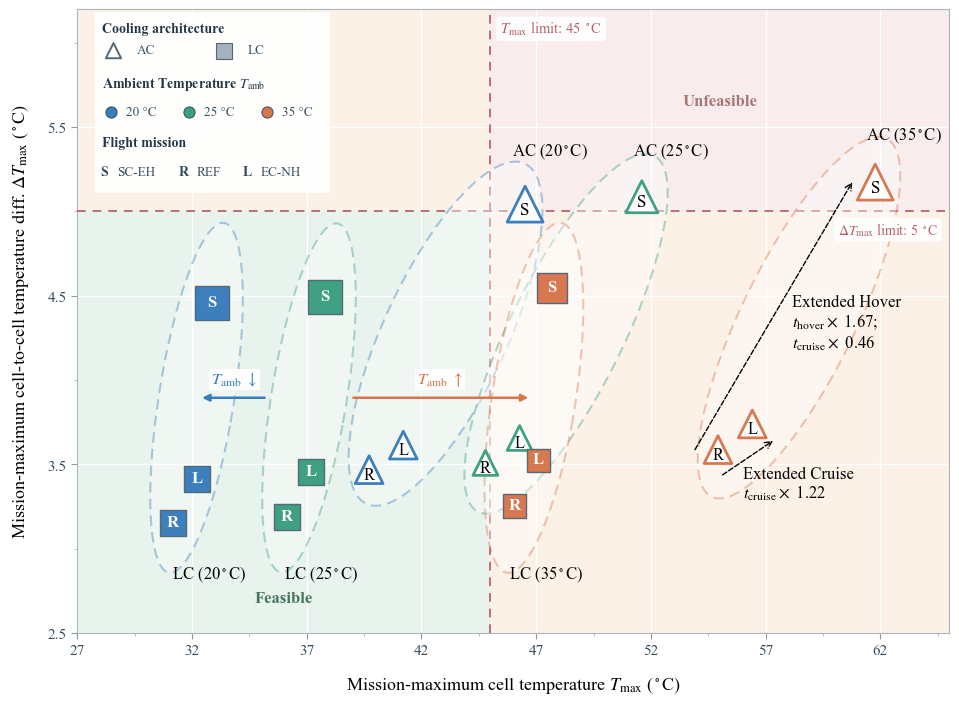

PNG: D:\eBATS\out\C0010\C0010R02_PARK25_ACLC_INTG_1D_CMP_thermal_feasibility.png
PDF: D:\eBATS\out\C0010\C0010R02_PARK25_ACLC_INTG_1D_CMP_thermal_feasibility.pdf


In [8]:
# Figure 17: create the figure, plot cases, then add regions, outlines, arrows, and legends.
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Ellipse, FancyArrowPatch
from matplotlib.ticker import AutoMinorLocator
from matplotlib.text import OffsetFrom
from matplotlib.transforms import Affine2D

font_size = 12

plt.rcParams.update({
    'font.family': 'Times New Roman',
    'mathtext.fontset': 'stix',
    'font.size': font_size,
    'axes.labelsize': font_size,
    'xtick.labelsize': font_size - 1,
    'ytick.labelsize': font_size - 1,
    'axes.linewidth': 0.9,
    'xtick.direction': 'in',
    'ytick.direction': 'in',
    'axes.unicode_minus': False,
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
})

# Create the canvas.
revision = 'R02'
figure_name = f'{CASE_ID}{revision}_PARK25_ACLC_INTG_1D_CMP_thermal_feasibility'

fig17 = plt.figure(figsize=(10.2, 7.7), facecolor='white')
ax = fig17.add_axes([0.115, 0.145, 0.855, 0.81])

# Select data and define the operating conditions.
cooling_markers = {'AC': {'marker':'^', 'area':400}, 'LC': {'marker':'s', 'area':350}}
ambient_colors = {20: '#397DBC', 25: '#3B9F80', 35: '#D8754D'}

mission_letters = {
    MISSIONS['short']['name']: 'S',
    MISSIONS['baseline']['name']: 'R',
    MISSIONS['long']['name']: 'L',
}

df = df_fig17.copy()
df['Mission_letter'] = df['Mission'].map(mission_letters)

xmin, xmax = 27.0, 65.0
ymin, ymax = 2.5, 6.2
limits = dict(xlim=(xmin, xmax), ylim=(ymin, ymax), xticks=np.arange(xmin, xmax+1, 5), yticks=np.arange(ymin, ymax, 1))

# Visual group boundaries: center x/y, width, height (axes fractions), and angle (degrees).
# These outlines group cases; they do not represent confidence or data ranges.
outline_layout = {
    ('AC', 20): (0.43, 0.45, 0.30, 0.12, 40.42),
    ('AC', 25): (0.58, 0.45, 0.32, 0.11, 40.69),
    ('AC', 35): (0.87, 0.46, 0.32, 0.11, 40.99),
    ('LC', 20): (0.12, 0.41, 0.23, 0.09, 70.15),
    ('LC', 25): (0.26, 0.41, 0.23, 0.09, 69.57),
    ('LC', 35): (0.54, 0.41, 0.23, 0.10, 69.79),
}

plot_dict = {}

for (cooling, ambient), group in df.groupby(['Cooling', 'Ambient_C'], sort=False):
   
    plot_dict[(cooling, ambient)] = {
        'data': group,
        'marker': cooling_markers[cooling]['marker'],
        'area': cooling_markers[cooling]['area'],
        'color': ambient_colors[ambient],
        'outline': outline_layout[(cooling, ambient)],
    }

# Plot each operating-condition group and its mission letters.

# Define styles before adding plot elements.
scatter_style = dict(edgecolor='#344D5C', linewidth=1.15, alpha=0.98, zorder=5)
marker_text_style = dict(
    textcoords='offset points', 
    ha='center', 
    va='center', 
    fontsize=font_size, 
    # fontweight='heavy', 
    zorder=6)

# determine the area based on the duration of hover stage
# get the hover duration of the base mission
hover_ref = MISSIONS['baseline']['hover']
end_ref = MISSIONS['baseline']['end']
ratio_hover_ref = hover_ref / end_ref

for key, value in plot_dict.items():
    cooling, ambient = key
    group = value['data']

    print(f"Processing group with {len(group)} cases: cooling={cooling}, ambient={ambient}")
    val_temperature = group['Tmax_C']
    val_difference = group['DTmax_C']
    area_ref = value['area']
    
    areas = []
    for item in group.itertuples(index=False):
        hover_ratio = item.hover / hover_ref
        area = area_ref * hover_ratio  # Example scaling factor for the area.
        areas.append(area)
    
    if cooling == 'AC':
        scatter_style['facecolor'] = 'white'    
        scatter_style['edgecolor'] = value['color']
        scatter_style['linewidth'] = 2
    else:
        scatter_style['facecolor'] = value['color']
        scatter_style['edgecolor'] = '#536875',
        scatter_style['linewidth'] = 1
    
    scaling = 0.80 if (cooling == 'AC' and ambient == 25) or (cooling == 'LC' and ambient == 35) else 1.0
    
    ax.scatter(
        val_temperature,
        val_difference,
        marker=value['marker'],
        color=value['color'],
        s=[area * scaling for area in areas],
        **scatter_style
    )

    for item in group.itertuples(index=False):
        offset = (0, -4) if cooling == 'AC' else (0, 0)        
        text_color = 'black' if cooling == 'AC' else 'white'
        marker_text_style['fontweight'] = 'normal' if cooling == 'AC' else 'bold'

        ax.annotate(
            item.Mission_letter,
            (item.Tmax_C, item.DTmax_C),
            xytext=offset,
            color=text_color,
            **marker_text_style
        )

# Add the four constraint-region backgrounds.
regions = [
    (xmin, ymin, T_LIMIT - xmin, DT_LIMIT - ymin, '#E7F3EC'),
    (xmin, DT_LIMIT, T_LIMIT - xmin, ymax - DT_LIMIT, '#FCF1E7'),
    (T_LIMIT, ymin, xmax - T_LIMIT, DT_LIMIT - ymin, '#FCF1E7'),
    (T_LIMIT, DT_LIMIT, xmax - T_LIMIT, ymax - DT_LIMIT, '#F8ECEC'),
]

background_style = dict(edgecolor='none', zorder=0)
for x, y, width, height, color in regions:
    ax.add_patch(
        Rectangle((x, y), width, height, facecolor=color, **background_style)
    )

# Add limit lines and region labels.
limit_style = dict(color='#B75E66', linewidth=1.25, linestyle=(0, (5, 4)), zorder=3)
ax.axvline(T_LIMIT, **limit_style)
ax.axhline(DT_LIMIT, **limit_style)

ax.annotate(
    rf'$T_{{\max}}$ limit: {T_LIMIT:g} $^\circ$C',
    (T_LIMIT, ymax),
    xytext=(7, -8),
    textcoords='offset points',
    ha='left',
    va='top',
    color=limit_style['color'],
    fontsize=font_size - 1.5,
    bbox=dict(boxstyle='round,pad=0.25', fc='white', ec='none', alpha=0.95),
    zorder=4
)

# Add the six group outlines using their fixed layout.
# The layout uses the original 28-63 C / 0-9.5 C reference coordinates.
outline_style = dict(facecolor='white', fill=True, linewidth=1.5, linestyle=(0, (5, 3)), alpha=0.4, zorder=3)
outline_transform = Affine2D().scale(35, 9.5).translate(28, 0) + ax.transData
group_outlines = {}

for key, value in plot_dict.items():
    cx, cy, width, height, angle = value['outline']

    cooling, Tamb = key
    
    if cooling == 'AC':
        # outline_style['linestyle'] = (0, (5, 3))
        xy_text_offset = (0.13, 0.114)
        # outline_style['facecolor'] = "none"
        
    if cooling == 'LC':
        # outline_style['linestyle'] = (0,(5,3))
        xy_text_offset = (0.015, -0.11)
        # outline_style['facecolor'] = 'none'

    outline = Ellipse(
        (cx, cy),
        width=width,
        height=height,
        angle=angle,
        transform=outline_transform,
        edgecolor=value['color'],
        **outline_style
    )

    ax.add_patch(
        outline
    )
    group_outlines[key] = outline
    
    # add annotation for the group
    label = rf"{cooling} ({Tamb}$^\circ$C)"
        
    ax.annotate(
        label,
        xy=(cx+xy_text_offset[0], cy+xy_text_offset[1]),
        xycoords=outline_transform,
        ha='center',
        va='center',
        fontsize=font_size,
        # fontweight='bold',
        zorder=6
    )

# Add temperature-change arrows between the green, blue, and orange groups.
arrow_style = dict(connectionstyle='arc3,rad=0', arrowstyle='-|>', mutation_scale=10, linewidth=1.8, shrinkA=4, shrinkB=4, zorder=8)
arrow_text_style = dict(
    xytext=(0, 7),
    textcoords='offset points',
    ha='center',
    va='bottom',
    fontsize=font_size,
    bbox=dict(facecolor='white', edgecolor='none', alpha=0.95, pad=1.5),
    zorder=8
)

for cooling in cooling_markers:
    if cooling == 'AC':
        continue
    
    source = group_outlines[(cooling, 25)]
    
    for ambient in (20, 35):
        target = group_outlines[(cooling, ambient)]
        src = (source.center[0], source.center[1])
        tgt = (target.center[0], source.center[1]) # Use the source.y to keep the arrow horizontal
        # print(f"Drawing arrow from {src} to {tgt}")        
        
        arrow = FancyArrowPatch(
            src,
            tgt, 
            patchA=source,
            # patchB=target,
            transform=outline_transform,
            color=ambient_colors[ambient],
            **arrow_style
        )

        ax.add_patch(arrow) 
        
        label_arrow = r'$T_{\mathrm{amb}}$ $\downarrow$' if ambient == 20 else r'$T_{\mathrm{amb}}$ $\uparrow$'
        # if cooling == 'AC':
        path = arrow.get_path().vertices
        label_position = (path[0] + path[2]) / 2       
        
        ax.annotate(
            label_arrow, 
            xy=label_position, 
            xycoords=outline_transform, 
            color=ambient_colors[ambient], 
            **arrow_text_style)

# Add the detached direction guide inside the AC / 20 C outline.
group = plot_dict[('AC', 35)]['data'].set_index('Mission_letter')

pos_B = group.loc['R', ['Tmax_C', 'DTmax_C']].to_numpy(dtype=float)
pos_S = group.loc['S', ['Tmax_C', 'DTmax_C']].to_numpy(dtype=float)
pos_L = group.loc['L', ['Tmax_C', 'DTmax_C']].to_numpy(dtype=float)

hover_B = 180
cruise_B = 1380

guide_dict ={
    "S": dict(
        start=(pos_B[0]-1, pos_B[1]),
        end=(pos_S[0]-1, pos_S[1]),
        xytext=(70, 70),
        hover=300,
        cruise=633       
    ),
    "L": dict(
        start=(pos_B[0]+0.2, pos_B[1]-0.15),
        end=(pos_L[0]+0.9, pos_L[1]-0.1),
        xytext=(15, -20),
        hover=180,
        cruise=1680        
    )
}

guide_arrow_style = dict(
    arrowstyle='->', 
    connectionstyle='arc3,rad=0', 
    linestyle='--',
    linewidth=1.0, 
    mutation_scale=12, 
    shrinkA=0, 
    shrinkB=0,
    zorder=7
)

guide_arrow_text_style = dict(
    xytext=(10, 30),
    textcoords='offset points',
    ha='left',
    va='bottom',
    fontsize=font_size,
    # fontweight='bold',
    # bbox=dict(facecolor='white', edgecolor='none', alpha=0.95, pad=1.5),
    zorder=7
)

for k, val in guide_dict.items():
    p_start = val['start']
    p_end = val['end']
    p_mean = (np.array(p_start) + np.array(p_end)) / 2    
    
    print(f"plotting an arrow from[{p_start}] to [{p_end}], mean at [{p_mean}]")

    arrow_style = guide_arrow_style.copy()

    guide_arrow = FancyArrowPatch(
        p_start,
        p_end,
        **arrow_style
    )
    ax.add_patch(guide_arrow)

    text_style = guide_arrow_text_style.copy()
    text_style['xytext'] = val['xytext']
    
    if k == 'S':             
        label = "Extended Hover" + '\n' \
                + rf'$t_\mathrm{{hover}} \times$ {val["hover"]/hover_B:.2f};' + '\n' \
                + rf'$t_\mathrm{{cruise}} \times$ {val["cruise"]/cruise_B:.2f}'
    elif k == 'L':
        label = "Extended Cruise" + '\n' \
                + rf'$t_\mathrm{{cruise}} \times$ {val["cruise"]/cruise_B:.2f}'        
    
    ax.annotate(
        label,
        xy=p_start,
        xycoords='data',
        **text_style,
    )


ax.annotate(
    rf'$\Delta T_{{\max}}$ limit: {DT_LIMIT:g} $^\circ$C',
    (xmax, DT_LIMIT),
    xytext=(-8, -7),
    textcoords='offset points',
    ha='right',
    va='top',
    color=limit_style['color'],
    fontsize=font_size - 2,
    bbox=dict(boxstyle='round,pad=0.25', fc='white', ec='none', alpha=0.9),
    zorder=4
)

region_labels = [
    ((xmin + T_LIMIT) / 2, ymin + 0.20, 'Feasible', '#43765B'),
    ((T_LIMIT + xmax) / 2, ymax - 0.55, 'Unfeasible', '#A77575'),
]

region_text_style = dict(ha='center', va='center', fontsize=font_size, fontweight='bold')

for x, y, label, color in region_labels:
    ax.text(x, y, label, color=color, **region_text_style)

# Set axes and grids.
ax.set(**limits)

ax.set_xlabel(r'Mission-maximum cell temperature $T_{\max}$ ($^\circ$C)', fontsize=font_size + 1, labelpad=12)
ax.set_ylabel(r'Mission-maximum cell-to-cell temperature diff. $\Delta T_{\max}$ ($^\circ$C)', fontsize=font_size + 1, labelpad=12)

for axis in (ax.xaxis, ax.yaxis):
    axis.set_minor_locator(AutoMinorLocator(2))

ax.tick_params(which='major', direction='out', length=4, color='#8B99A2', labelcolor='#344D5C', top=False, right=False)
ax.tick_params(which='minor', direction='out', length=2, color='#AAB5BD')

ax.grid(which='major', color='white', linewidth=0.95)
ax.set_axisbelow(True)

ax.spines[:].set_color('#AAB5BD')
ax.spines[:].set_linewidth(0.8)


# Compact legends in the upper-left corner of the main axes.
panel = ax.inset_axes([0.02, 0.69, 0.27, 0.29], zorder=10)
panel.set(xlim=(0, 1), ylim=(0, 1))
panel.axis('off')

panel.add_patch(
    Rectangle((0, 0.052), 1, 1, transform=panel.transAxes, facecolor='white', edgecolor='none', alpha=0.95, clip_on=False, zorder=0)
)

heading_style = dict(fontsize=font_size - 2, fontweight='bold', color='#243746', va='center')
label_style = dict(va='center', fontsize=font_size - 2.5, color='#344D5C')

panel.text(0.03, 0.96, 'Cooling architecture', **heading_style)

for x, cooling in [(0.08, 'AC'), (0.55, 'LC')]:
    panel.scatter(
        x,
        0.84,
        s=120,
        marker=cooling_markers[cooling]['marker'],
        color= '#A5B2BC' if cooling == 'LC' else 'none',
        edgecolor='#536875',
        linewidth=0.8 if cooling == 'LC' else 1.4
    )
    
    # panel.annotate(
    #         'R',
    #         xy = (x, 0.83),
    #         # xytext=(0.0, 0.0),
    #         color='black' if cooling == 'AC' else 'white',
    #         ha='center',
    #         va='center',
    #         fontsize=font_size - 3,
    #         # **marker_text_style
    #     )
    
    panel.text(x + 0.1, 0.84, cooling, **label_style)

y_text = 0.66
y_offset = 0.16

panel.text(0.03, y_text, r'Ambient Temperature $T_{\mathrm{amb}}$', **heading_style)

for x, ambient in [(0.07, 20), (0.40, 25), (0.73, 35)]:
    panel.scatter(
        x,
        y_text - y_offset,
        s=65,
        color=ambient_colors[ambient],
        edgecolor='#344D5C',
        linewidth=0.7
    )
    panel.text(x + 0.065, y_text - y_offset, f'{ambient} °C', **label_style)

y_text = 0.33

panel.text(0.03, y_text, 'Flight mission', **heading_style)

for x, letter, label in [(0.04, 'S', 'SC-EH'), (0.38, 'R', 'REF'), (0.65, 'L', 'EC-NH')]:
    panel.text(
        x,
        y_text - y_offset,
        letter,
        ha='center',
        va='center',
        fontsize=font_size - 2,
        fontweight='bold',
        color='#344D5C'
    )
    panel.text(x + 0.055, y_text - y_offset, label, **label_style)


# Save and display.
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

png_file = OUTPUT_DIR / f'{figure_name}.png'
pdf_file = OUTPUT_DIR / f'{figure_name}.pdf'

for figure_file in (png_file, pdf_file):
    fig17.savefig(figure_file, dpi=DPI, bbox_inches='tight', facecolor='white')

plt.show()

print('PNG:', png_file)
print('PDF:', pdf_file)
